In [1]:
# DATA MINING 1
# CLASSIFICATION & REGRESSION

In [2]:
# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE

# Base
import math
import os
from math import sqrt

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)

'''# Pattern Mining
from fim import (
    fpgrowth,
    apriori,
)'''

# Xmeans
from pyclustering.cluster import xmeans

os.environ['LOKY_MAX_CPU_COUNT'] = '12'

In [3]:
# CARICAMENTO DATAFRAME

# Base e Cleaned
df = pd.read_csv("DM1_game_dataset.csv")
df_cleaned = pd.read_csv("df_cleaned.csv")

# Train & Test
train_set = pd.read_csv("train_set.csv")
test_set = pd.read_csv("test_set.csv")

# Imputed
train_imputed = pd.read_csv("train_imputed.csv")
test_imputed = pd.read_csv("test_imputed.csv")

# Transformed
train_transformed = pd.read_csv("train_transformed.csv")
test_transformed = pd.read_csv("test_transformed.csv")

In [4]:
# Identificazione Colonne

# Qualitative
colonne_quali = df_cleaned.select_dtypes(include=["object"]).columns
colonne_quali = colonne_quali + ["BGGId"]

# Ranking
colonne_rank = [
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames"
]
# Categorie
colonne_cat = ["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
               "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"]

# Binarie
colonne_binarie = ["Kickstarted", "IsReimplementation", "RatingBinaria"]

# Quantitative
colonne_quanti = df_cleaned.select_dtypes(
    include=["int64", "float64"]).columns

# Numeriche
colonne_numeriche = (
    colonne_quanti.tolist()
)
colonne_numeriche = list(dict.fromkeys(colonne_numeriche))

In [5]:
# Misc

# Stile Grafici
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4)

# Scalers
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Numerosità
n_train = len(train_set["Rating"])
n_test = len(test_set["Rating"])

In [6]:
# -----------------------------------------------
# -----------------------------------------------
# CLASSIFICATION

In [7]:
# Selezione Variabili per TREE

train_imputed2 = train_imputed.drop(["BGGId", "RatingDiscreta"], axis=1)


def calculate_eta_squared(train_imputed2, cat_col, num_col):
    """
    Calcola l'Eta Quadrato (η²) tra una variabile categorica e una numerica.
    η² misura la proporzione di varianza della variabile numerica spiegata dalla categorica.
    """
    # Raggruppa i valori numerici per ogni categoria
    groups = [train_imputed2[train_imputed2[cat_col] == c][num_col]
              for c in train_imputed2[cat_col].unique()]

    # Calcolo ANOVA one-way
    # stats.f_oneway restituisce (F-statistic, p-value)
    f_stat, p_val = stats.f_oneway(*groups)

    # Calcolo manuale di Eta Squared
    # Formula: SS_between / SS_total
    global_mean = train_imputed2[num_col].mean()
    ss_between = sum([len(g) * (g.mean() - global_mean)**2 for g in groups])
    ss_total = sum((train_imputed2[num_col] - global_mean)**2)

    eta_sq = ss_between / ss_total

    return eta_sq, p_val


# Identifica automaticamente le colonne numeriche (escludendo la categorica stessa)
numeric_cols = train_imputed2.select_dtypes(
    include=[np.number]).columns.tolist()

print(f"{'Variabile':<15} | {'Eta Squared (η²)':<18} | {'P-value (ANOVA)':<15}")
print("-" * 55)

results = []

for col in numeric_cols:
    eta, p = calculate_eta_squared(train_imputed2, 'Rating', col)
    results.append((col, eta, p))

# Ordina i risultati per Eta Squared decrescente (dalla relazione più forte alla più debole)
results.sort(key=lambda x: x[1], reverse=True)

for col, eta, p in results:
    sig = "*" if p < 0.05 else ""  # Asterisco se statisticamente significativo
    print(f"{col:<15} | {eta:.4f}             | {p:.4f} {sig}")

print("-" * 55)
print("* p-value < 0.05 indica che le medie dei gruppi sono significativamente diverse.")

# GameWeight, NumWant, MfgPlaytime, ComAgeRec, MinPlayers, NumUserRatings

Variabile       | Eta Squared (η²)   | P-value (ANOVA)
-------------------------------------------------------
GameWeight      | 0.2334             | 0.0000 *
NumWant         | 0.1390             | 0.0000 *
MfgPlaytime     | 0.1051             | 0.0000 *
NumWish         | 0.1038             | 0.0000 *
ComAgeRec       | 0.0958             | 0.0000 *
MediaPlaytime   | 0.0790             | 0.0000 *
ComMinPlaytime  | 0.0413             | 0.0000 *
NumOwned        | 0.0377             | 0.0000 *
MinPlayers      | 0.0364             | 0.0000 *
NumUserRatings  | 0.0352             | 0.0000 *
MfgAgeRec       | 0.0332             | 0.0000 *
NumWeightVotes  | 0.0227             | 0.0000 *
NumExpansions   | 0.0214             | 0.0000 *
NumImplementations | 0.0081             | 0.0000 *
YearPublished   | 0.0055             | 0.0000 *
Age             | 0.0055             | 0.0000 *
LanguageEase    | 0.0037             | 0.0000 *
MaxPlayers      | 0.0035             | 0.0000 *
NumAlternates   | 0.00

In [8]:
# Partitioning (già fatto) & Data PER TREE

train_classification_tree = train_imputed.copy()
test_classification_tree = test_imputed.copy()

colonnette_tree = ["GameWeight", "NumWant",
                   "MediaPlaytime", "ComAgeRec", "MinPlayers", "NumUserRatings", "Rating"]
train_classification_tree = train_classification_tree[colonnette_tree]
test_classification_tree = test_classification_tree[colonnette_tree]

x_train_tree = train_classification_tree.drop("Rating", axis=1)
y_train_tree = train_classification_tree["Rating"]

x_test_tree = test_classification_tree.drop("Rating", axis=1)
y_test_tree = test_classification_tree["Rating"]

In [9]:
# Dataset Creation per NON tree

train_transformed2 = train_transformed.drop(
    ["BGGId", "RatingDiscreta"], axis=1)


def calculate_eta_squared(train_transformed2, cat_col, num_col):
    """
    Calcola l'Eta Quadrato (η²) tra una variabile categorica e una numerica.
    η² misura la proporzione di varianza della variabile numerica spiegata dalla categorica.
    """
    # Raggruppa i valori numerici per ogni categoria
    groups = [train_transformed2[train_transformed2[cat_col] == c][num_col]
              for c in train_transformed2[cat_col].unique()]

    # Calcolo ANOVA one-way
    # stats.f_oneway restituisce (F-statistic, p-value)
    f_stat, p_val = stats.f_oneway(*groups)

    # Calcolo manuale di Eta Squared
    # Formula: SS_between / SS_total
    global_mean = train_transformed2[num_col].mean()
    ss_between = sum([len(g) * (g.mean() - global_mean)**2 for g in groups])
    ss_total = sum((train_transformed2[num_col] - global_mean)**2)

    eta_sq = ss_between / ss_total

    return eta_sq, p_val


# Identifica automaticamente le colonne numeriche (escludendo la categorica stessa)
numeric_cols = train_transformed2.select_dtypes(
    include=[np.number]).columns.tolist()

print(f"{'Variabile':<15} | {'Eta Squared (η²)':<18} | {'P-value (ANOVA)':<15}")
print("-" * 55)

results = []

for col in numeric_cols:
    eta, p = calculate_eta_squared(train_transformed2, 'Rating', col)
    results.append((col, eta, p))

# Ordina i risultati per Eta Squared decrescente (dalla relazione più forte alla più debole)
results.sort(key=lambda x: x[1], reverse=True)

for col, eta, p in results:
    sig = "*" if p < 0.05 else ""  # Asterisco se statisticamente significativo
    print(f"{col:<15} | {eta:.4f}             | {p:.4f} {sig}")

print("-" * 55)
print("* p-value < 0.05 indica che le medie dei gruppi sono significativamente diverse.")

Variabile       | Eta Squared (η²)   | P-value (ANOVA)
-------------------------------------------------------
NumWish         | 0.3145             | 0.0000 *
NumWant         | 0.3090             | 0.0000 *
GameWeight      | 0.2334             | 0.0000 *
Age             | 0.1588             | 0.0000 *
MfgPlaytime     | 0.1051             | 0.0000 *
MediaPlaytime   | 0.0962             | 0.0000 *
ComAgeRec       | 0.0958             | 0.0000 *
NumExpansions   | 0.0941             | 0.0000 *
NumOwned        | 0.0864             | 0.0000 *
NumUserRatings  | 0.0794             | 0.0000 *
NumWeightVotes  | 0.0510             | 0.0000 *
MinPlayers      | 0.0495             | 0.0000 *
ComMinPlaytime  | 0.0413             | 0.0000 *
MfgAgeRec       | 0.0332             | 0.0000 *
MaxPlayers      | 0.0237             | 0.0000 *
NumImplementations | 0.0181             | 0.0000 *
LanguageEase    | 0.0037             | 0.0000 *
YearPublished   | 0.0015             | 0.0000 *
NumAlternates   | 0.00

In [10]:
# Partitioning (già fatto) & Data NON TREE


train_classification = train_transformed.copy()
test_classification = test_transformed.copy()

colonnette = ["GameWeight", "NumWish",
              "MediaPlaytime", "ComAgeRec", "NumExpansions", "Rating"]
train_classification = train_classification[colonnette]
test_classification = test_classification[colonnette]

x_train = train_classification.drop("Rating", axis=1)
y_train = train_classification["Rating"]

x_test = test_classification.drop("Rating", axis=1)
y_test = test_classification["Rating"]

x_train = standard_scaler.fit_transform(x_train)
x_test = standard_scaler.fit_transform(x_test)


Overall error estimate: 0.3710263929618768

Accuracy Cross: 0.6290 (+/- 0.01)

Accuracy Test: 0.638752052545156
              precision    recall  f1-score   support

        High       0.69      0.48      0.57       987
         Low       0.68      0.68      0.68      1387
      Medium       0.59      0.70      0.64      1889

    accuracy                           0.64      4263
   macro avg       0.66      0.62      0.63      4263
weighted avg       0.65      0.64      0.64      4263



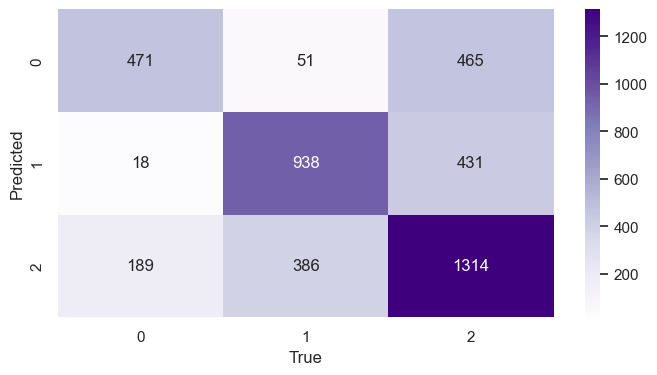

In [11]:
# Knn Classifier  k = sqrt(n)

k1 = round(sqrt(n_train))
knn_class = KNeighborsClassifier(
    n_neighbors=k1, metric="euclidean", weights="distance")
knn_class.fit(x_train, y_train)

# Cross Validation
scores = cross_val_score(knn_class, x_train, y_train, cv=10)
print("\nOverall error estimate:", 1 - scores.mean())
print('\nAccuracy Cross: %0.4f (+/- %0.2f)' % (scores.mean(), scores.std()))
cross_val_score(knn_class, x_train, y_train, cv=k1, scoring='f1_macro')
y_test_pred_knn = knn_class.predict(x_test)

# Accuracy
print("\nAccuracy Test:", accuracy_score(y_test, y_test_pred_knn))

# Confusion Matrics
print(classification_report(y_test, y_test_pred_knn))
cf_knn = confusion_matrix(y_test, y_test_pred_knn)
sns.heatmap(cf_knn, annot=True, cmap="Purples", fmt="d")
plt.xlabel("True")
plt.ylabel("Predicted")
plt.show()


# Esportazione
knn_standard = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_test_pred_knn
})

y_prob = knn_class.predict_proba(x_test)
knn_standard['Prob_Class_0'] = y_prob[:, 0]
knn_standard['Prob_Class_1'] = y_prob[:, 1]
knn_standard["Prob_Class_2"] = y_prob[:, 2]

knn_standard.to_csv('knn_standard.csv', index=False)

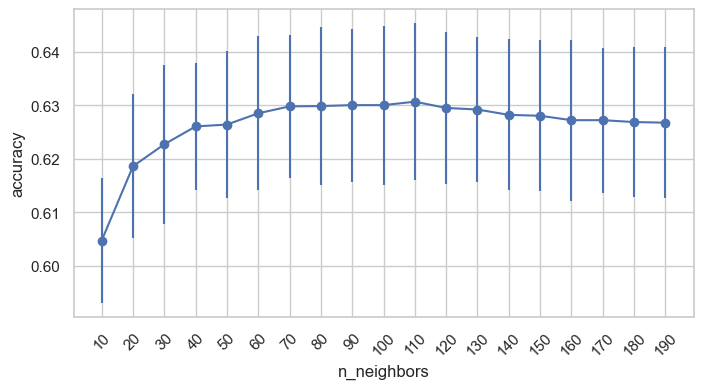

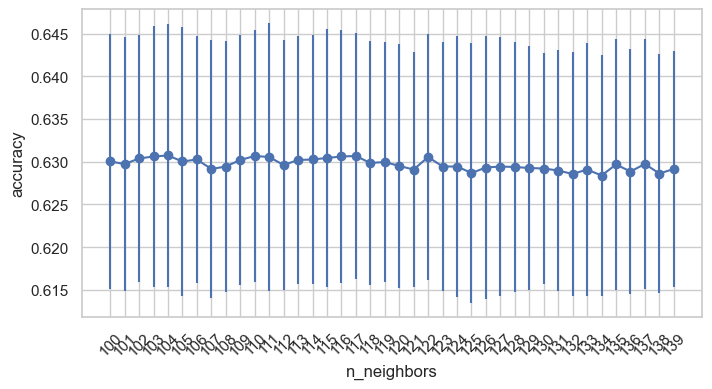

4


In [12]:
# Ricerca miglior K

# Tuning
n_neighbors = range(10, 200, 10)
avg_scores = list()
std_scores = list()

for n in n_neighbors:
    clf = KNeighborsClassifier(
        n_neighbors=n, metric="euclidean", weights="distance")
    scores = cross_val_score(clf, x_train, y_train, cv=10)
    avg_scores.append(np.mean(scores))
    std_scores.append(np.std(scores))

# plt.plot(avg_scores)
plt.errorbar(range(len(n_neighbors)), y=avg_scores,
             yerr=std_scores, marker='o')
plt.xticks(range(len(n_neighbors)), n_neighbors)
plt.xlabel("n_neighbors")
plt.ylabel("accuracy")
plt.xticks(rotation=45)
plt.show()

# Tuning 2
n_neighbors2 = range(100, 140)
avg_scores2 = list()
std_scores2 = list()

for n in n_neighbors2:
    clf = KNeighborsClassifier(
        n_neighbors=n, metric="euclidean", weights="distance")
    scores = cross_val_score(clf, x_train, y_train, cv=10)
    avg_scores2.append(np.mean(scores))
    std_scores2.append(np.std(scores))

# plt.plot(avg_scores)
plt.errorbar(range(len(n_neighbors2)), y=avg_scores2,
             yerr=std_scores2, marker='o')
plt.xticks(range(len(n_neighbors2)), n_neighbors2)
plt.xlabel("n_neighbors")
plt.ylabel("accuracy")
plt.xticks(rotation=45)
plt.show()

print(avg_scores2.index(max(avg_scores2)))
# MILGIORE k = 119


Overall error estimate: 0.37079178885630504

Accuracy Cross: 0.6292 (+/- 0.01)

Accuracy Test: 0.6373445930096177
              precision    recall  f1-score   support

        High       0.69      0.48      0.56       987
         Low       0.68      0.68      0.68      1387
      Medium       0.59      0.69      0.64      1889

    accuracy                           0.64      4263
   macro avg       0.66      0.62      0.63      4263
weighted avg       0.64      0.64      0.63      4263



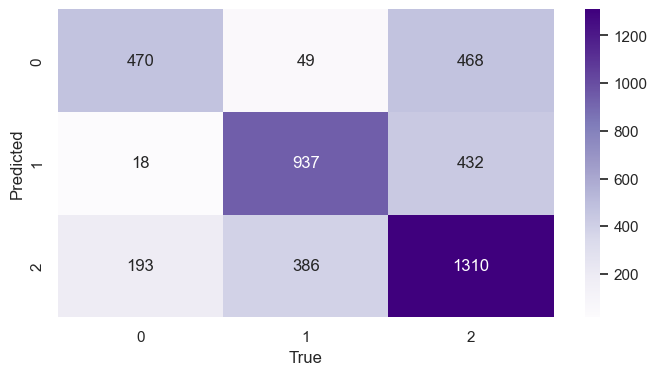

In [13]:
# Knn Classifier  k= 130

k2 = 130
knn_class = KNeighborsClassifier(
    n_neighbors=k2, metric="euclidean", weights="distance")
knn_class.fit(x_train, y_train)

# Cross Validation
scores = cross_val_score(knn_class, x_train, y_train, cv=10)
print("\nOverall error estimate:", 1 - scores.mean())
print('\nAccuracy Cross: %0.4f (+/- %0.2f)' % (scores.mean(), scores.std()))
cross_val_score(knn_class, x_train, y_train, cv=k2, scoring='f1_macro')
y_test_pred_knn = knn_class.predict(x_test)

# Accuracy
print("\nAccuracy Test:", accuracy_score(y_test, y_test_pred_knn))

# Confusion Matrics
print(classification_report(y_test, y_test_pred_knn))
cf_knn = confusion_matrix(y_test, y_test_pred_knn)
sns.heatmap(cf_knn, annot=True, cmap="Purples", fmt="d")
plt.xlabel("True")
plt.ylabel("Predicted")
plt.show()


# Esportazione
knn_best = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_test_pred_knn
})

y_prob = knn_class.predict_proba(x_test)
knn_best['Prob_Class_0'] = y_prob[:, 0]
knn_best['Prob_Class_1'] = y_prob[:, 1]
knn_best['Prob_Class_2'] = y_prob[:, 2]


knn_best.to_csv('knn_best.csv', index=False)

              precision    recall  f1-score   support

        High       0.56      0.58      0.57       987
         Low       0.58      0.75      0.66      1387
      Medium       0.58      0.45      0.51      1889

    accuracy                           0.58      4263
   macro avg       0.57      0.59      0.58      4263
weighted avg       0.58      0.58      0.57      4263


Accuracy Test: 0.5763546798029556


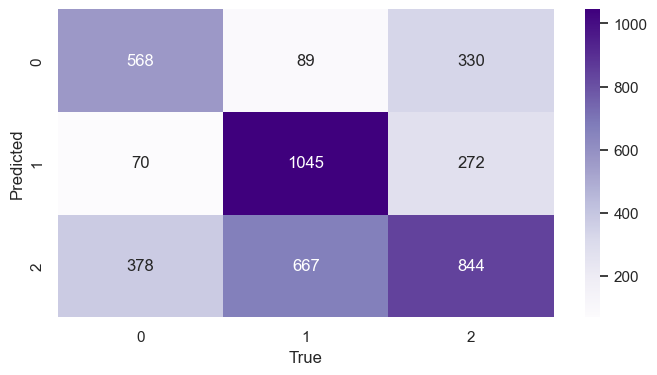

In [14]:
# Bayes

stoca_class = GaussianNB()
stoca_class.fit(x_train, y_train)
y_test_pred_stoca = stoca_class.predict(x_test)
y_test_pred_stoca
print(classification_report(y_test, y_test_pred_stoca))
stoca_class.predict_proba(x_test)

print("\nAccuracy Test:", accuracy_score(y_test, y_test_pred_stoca))

# Confusion Matrics
cf_stoca = confusion_matrix(y_test, y_test_pred_stoca)
sns.heatmap(cf_stoca, annot=True, cmap="Purples", fmt="d")
plt.xlabel("True")
plt.ylabel("Predicted")
plt.show()


# Esportazione
bayes = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_test_pred_stoca
})

y_prob_bayes = stoca_class.predict_proba(x_test)
bayes['Prob_Class_0'] = y_prob_bayes[:, 0]
bayes['Prob_Class_1'] = y_prob_bayes[:, 1]
bayes['Prob_Class_2'] = y_prob_bayes[:, 2]

bayes.to_csv('bayes.csv', index=False)

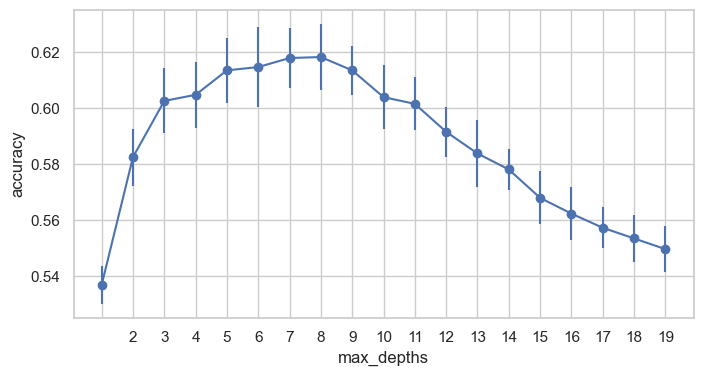

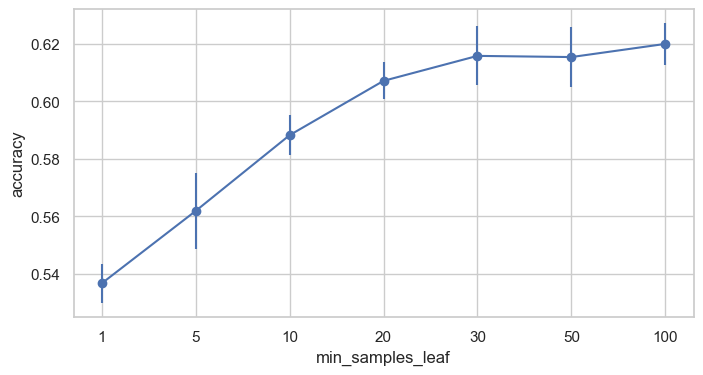

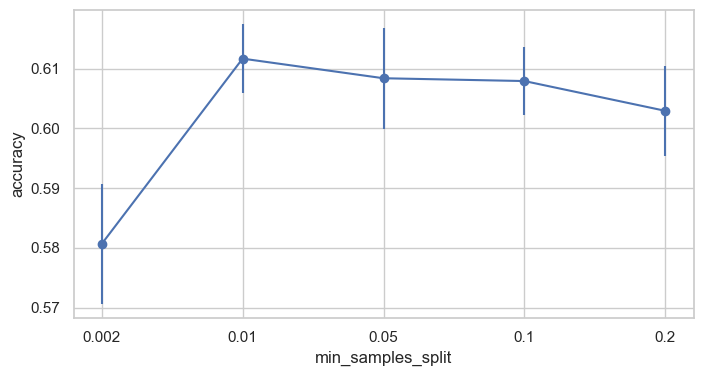

In [15]:
# Decison Tree Tuning

max_depths = [None] + list(np.arange(2, 20))
avg_scores = list()
std_scores = list()

for max_depth in max_depths:
    dt = DecisionTreeClassifier(max_depth=max_depth)
    scores = cross_val_score(dt, x_train_tree, y_train_tree, cv=10)
    avg_scores.append(np.mean(scores))
    std_scores.append(np.std(scores))

plt.errorbar(range(len(max_depths)), y=avg_scores, yerr=std_scores, marker='o')
plt.xticks(range(len(max_depths)), max_depths)
plt.xlabel("max_depths")
plt.ylabel("accuracy")
plt.show()

min_samples_leafs = [1, 5, 10, 20, 30, 50, 100]
avg_scores = list()
std_scores = list()

for min_samples_leaf in min_samples_leafs:
    dt = DecisionTreeClassifier(min_samples_leaf=min_samples_leaf)
    scores = cross_val_score(dt, x_train_tree, y_train_tree, cv=10)
    avg_scores.append(np.mean(scores))
    std_scores.append(np.std(scores))

plt.errorbar(range(len(min_samples_leafs)),
             y=avg_scores, yerr=std_scores, marker='o')
plt.xticks(range(len(min_samples_leafs)), min_samples_leafs)
plt.xlabel("min_samples_leaf")
plt.ylabel("accuracy")
plt.show()

min_samples_splits = [0.002, 0.01, 0.05, 0.1, 0.2]
avg_scores = list()
std_scores = list()

for min_samples_split in min_samples_splits:
    dt = DecisionTreeClassifier(min_samples_split=min_samples_split)
    scores = cross_val_score(dt, x_train_tree, y_train, cv=5)
    avg_scores.append(np.mean(scores))
    std_scores.append(np.std(scores))

plt.errorbar(range(len(min_samples_splits)),
             y=avg_scores, yerr=std_scores, marker='o')
plt.xticks(range(len(min_samples_splits)), min_samples_splits)
plt.xlabel("min_samples_split")
plt.ylabel("accuracy")
plt.show()

In [16]:
# Decision Tree

tree_class = DecisionTreeClassifier(
    criterion='gini', splitter="best", max_depth=7, min_samples_leaf=50, min_samples_split=0.01)
tree_class.fit(x_train_tree, y_train_tree)
plt.figure(figsize=(20, 4), dpi=1000)
plot_tree(tree_class, feature_names=colonnette, filled=True)
plt.show()

tree_class = DecisionTreeClassifier(
    criterion='gini', splitter="best", max_depth=3, min_samples_leaf=50, min_samples_split=0.01)
tree_class.fit(x_train_tree, y_train_tree)
plt.figure(figsize=(20, 4), dpi=1000)
plot_tree(tree_class, feature_names=colonnette, filled=True)
plt.show()

y_test_pred_tree = tree_class.predict(x_test_tree)
y_prob_tree = tree_class.predict_proba(x_test_tree)

# Esportazione
tree = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_test_pred_tree
})

tree['Prob_Class_0'] = y_prob_tree[:, 0]
tree['Prob_Class_1'] = y_prob_tree[:, 1]
tree['Prob_Class_2'] = y_prob_tree[:, 2]

tree.to_csv('tree.csv', index=False)

Train Accuracy 0.6045747800586511
Train F1-score [0.53935326 0.67069861 0.57554448]

Test Accuracy 0.5998123387285949
Test F1-score [0.53804017 0.66995074 0.5650619 ]
              precision    recall  f1-score   support

        High       0.67      0.45      0.54       987
         Low       0.58      0.78      0.67      1387
      Medium       0.59      0.54      0.57      1889

    accuracy                           0.60      4263
   macro avg       0.62      0.59      0.59      4263
weighted avg       0.61      0.60      0.59      4263



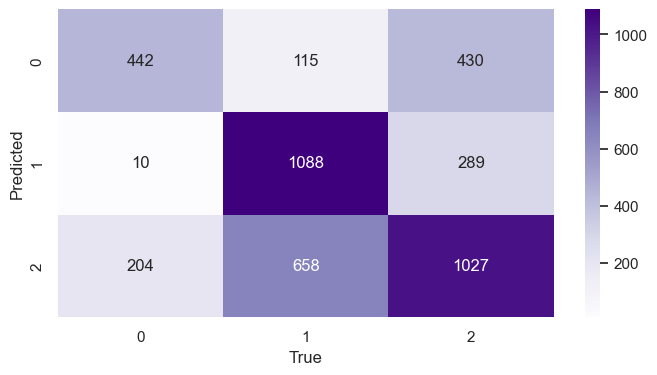

In [17]:
# Cunfusion Matrix

y_train_pred_tree = tree_class.predict(x_train_tree)
y_test_pred_tree = tree_class.predict(x_test_tree)

print('Train Accuracy %s' % accuracy_score(y_train_tree, y_train_pred_tree))
print('Train F1-score %s' %
      f1_score(y_train_tree, y_train_pred_tree, average=None))
print()

print('Test Accuracy %s' % accuracy_score(y_test_tree, y_test_pred_tree))
print('Test F1-score %s' % f1_score(y_test_tree, y_test_pred_tree, average=None))

print(classification_report(y_test_tree, y_test_pred_tree))

cf_tree = confusion_matrix(y_test_tree, y_test_pred_tree)
sns.heatmap(cf_tree, annot=True, cmap="Purples", fmt="d")
plt.xlabel("True")
plt.ylabel("Predicted")
plt.show()

In [18]:
# -----------------------------------------------
# -----------------------------------------------
# REGRESSION

In [19]:
# Dataset creation

colonne_numeriche2 = colonne_numeriche.copy()
colonne_numeriche2.remove("BGGId")
colonne_numeriche2.remove("RatingDiscreta")
colonne_numeriche2.remove("ComMinPlaytime")
colonne_numeriche2.remove("MfgPlaytime")
colonne_numeriche2.remove("YearPublished")

# Imputed
train_reg_imp = train_imputed[colonne_numeriche2].copy()
test_reg_imp = test_imputed[colonne_numeriche2].copy()

reg_x_train_imp = train_reg_imp.drop(["MediaPlaytime"], axis=1)
reg_y_train_imp = train_reg_imp["MediaPlaytime"]

reg_x_test_imp = test_reg_imp.drop(["MediaPlaytime"], axis=1)
reg_y_test_imp = test_reg_imp["MediaPlaytime"]


# Transformed
train_reg_tra = train_transformed[colonne_numeriche2].copy()
test_reg_tra = test_transformed[colonne_numeriche2].copy()

reg_x_train_tra = train_reg_tra.drop(["MediaPlaytime"], axis=1)
reg_y_train_tra = train_reg_tra["MediaPlaytime"]

reg_x_test_tra = test_reg_tra.drop(["MediaPlaytime"], axis=1)
reg_y_test_tra = test_reg_tra["MediaPlaytime"]


# Transformed Scaled
train_reg_tra_sca_0 = standard_scaler.fit_transform(train_reg_tra)
test_reg_tra_sca_0 = standard_scaler.fit_transform(test_reg_tra)

train_reg_tra_sca = pd.DataFrame(
    train_reg_tra_sca_0,
    # Prendi i nomi delle colonne dal DataFrame originale
    columns=train_reg_tra.columns,
    # (Opzionale) Mantieni gli indici originali
    index=train_reg_tra.index
)
test_reg_tra_sca = pd.DataFrame(
    test_reg_tra_sca_0,
    # Prendi i nomi delle colonne dal DataFrame originale
    columns=test_reg_tra.columns,
    # (Opzionale) Mantieni gli indici originali
    index=test_reg_tra.index
)

reg_x_train_tra_sca = train_reg_tra_sca.drop(["MediaPlaytime"], axis=1)
reg_y_train_tra_sca = train_reg_tra_sca["MediaPlaytime"]

reg_x_test_tra_sca = test_reg_tra_sca.drop(["MediaPlaytime"], axis=1)
reg_y_test_tra_sca = test_reg_tra_sca["MediaPlaytime"]

R^2 Score Training: 0.4892
Coefficiente (m): 0.7087
Intercetta (q): 2.3647
R^2 Score Test: 0.4986
RMSE Score Test: 44.6001
MAE Score Test: 26.8121


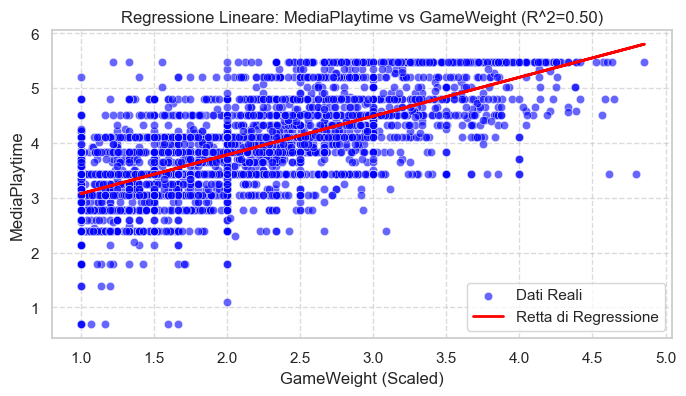

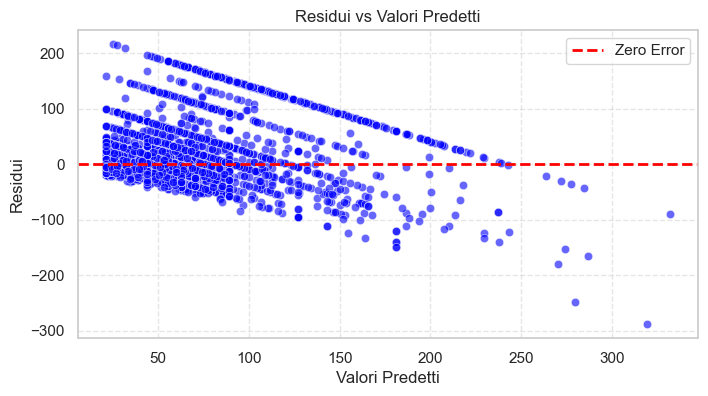

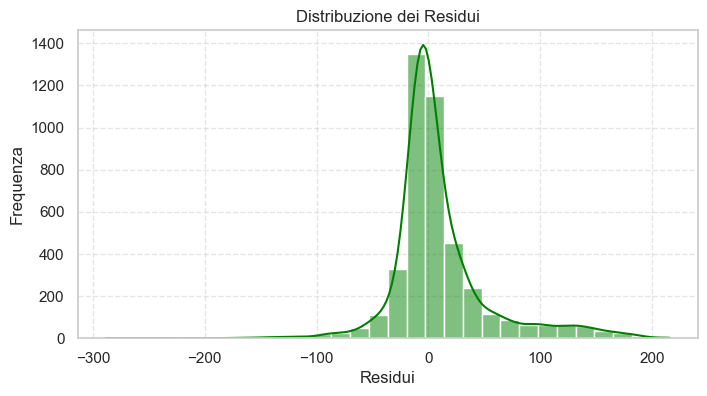

Media dei residui: 9.6566
Deviazione standard dei residui: 43.5472


In [20]:
# Regressione Lineare Semplice

reg = LinearRegression()

R2 = []
for col in reg_x_train_tra.columns:
    X_train = reg_x_train_tra[col].values.reshape(-1, 1)
    reg.fit(X_train, reg_y_train_tra)

    X_test = reg_x_test_tra[col].values.reshape(-1, 1)
    r2_prov = reg.score(X_test, reg_y_test_tra)
    R2.append(r2_prov)

# Modello e risultati Training
x_lin_sem_train = reg_x_train_tra[["GameWeight"]].values.reshape(-1, 1)
modello_lin_sem = reg.fit(x_lin_sem_train, reg_y_train_tra)
y_pred_lin_sem_train = reg.predict(x_lin_sem_train)
r2_lin_sem_train = reg.score(x_lin_sem_train, reg_y_train_tra)
print(f"R^2 Score Training: {r2_lin_sem_train:.4f}")
print(f"Coefficiente (m): {reg.coef_[0]:.4f}")
print(f"Intercetta (q): {reg.intercept_:.4f}")

# Test
x_lin_sem = reg_x_test_tra[["GameWeight"]].values.reshape(-1, 1)
y_pred_lin_sem = reg.predict(x_lin_sem)
r2_lin_sem = reg.score(x_lin_sem, reg_y_test_tra)

x_lin_sem_unt = np.exp(x_lin_sem)
reg_y_test_tra_unt = np.exp(reg_y_test_tra)
y_pred_lin_sem_unt = np.exp(y_pred_lin_sem)

rmse_lin_sem = np.sqrt(mean_squared_error(
    reg_y_test_tra_unt, y_pred_lin_sem_unt))
mae_lin_sem = mean_absolute_error(reg_y_test_tra_unt, y_pred_lin_sem_unt)
print(f"R^2 Score Test: {r2_lin_sem:.4f}")
print(f"RMSE Score Test: {rmse_lin_sem:.4f}")
print(f"MAE Score Test: {mae_lin_sem:.4f}")


# Grafico
sns.scatterplot(x=x_lin_sem.squeeze(), y=reg_y_test_tra,
                color="blue", alpha=0.6, label="Dati Reali")
# Retta di regressione
plt.plot(x_lin_sem, y_pred_lin_sem, color="red",
         linewidth=2, label="Retta di Regressione")
plt.title(
    f"Regressione Lineare: MediaPlaytime vs GameWeight (R^2={r2_lin_sem:.2f})")
plt.xlabel("GameWeight (Scaled)")
plt.ylabel("MediaPlaytime")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()


# Bontà Modello
residui_lin_sem = reg_y_test_tra_unt - y_pred_lin_sem_unt

# Residui vs Valori Predetti

sns.scatterplot(x=y_pred_lin_sem_unt.flatten(),
                y=residui_lin_sem, alpha=0.6, color='blue')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label="Zero Error")
plt.title("Residui vs Valori Predetti")
plt.xlabel("Valori Predetti")
plt.ylabel("Residui")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Distribuzione dei Residui
sns.histplot(residui_lin_sem, kde=True, color='green', bins=30)
plt.title("Distribuzione dei Residui")
plt.xlabel("Residui")
plt.ylabel("Frequenza")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Statistiche descrittive dei residui
# Dovrebbe essere vicina a 0
print(f"Media dei residui: {residui_lin_sem.mean():.4f}")
print(f"Deviazione standard dei residui: {residui_lin_sem.std():.4f}")

R^2 Score: 0.5858
Coefficienti (m): [ 4.65836649e-01  1.74242107e-02  1.24106024e-01  6.33980073e-02
 -3.69208947e-05  1.78533494e-01  9.57257354e-02 -4.59065297e-02
  9.02485834e-02  1.12906583e-02 -2.53589199e-01 -4.85694884e-02
 -1.76209152e-02  1.16171041e-03  1.38841259e-01]
Intercetta (q): 1.4999
R^2 Score Test: 0.5426
RMSE Score Test: 39.0501
MAE Score Test: 23.7201


c:\Users\Riccardo\anaconda3\Lib\site-packages\pandas\core\internals\blocks.py:393: RuntimeWarning: overflow encountered in exp
  result = func(self.values, **kwargs)


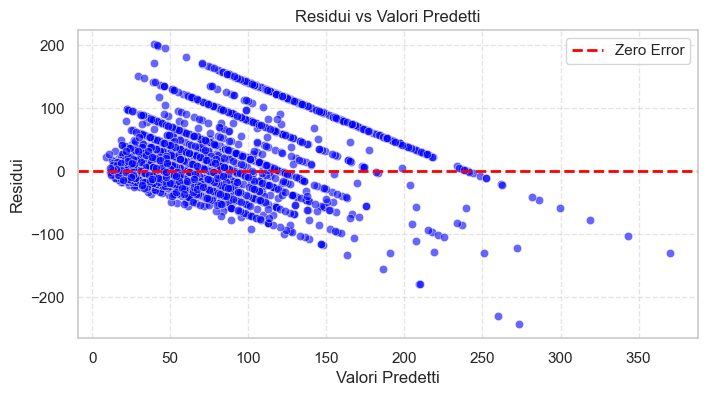

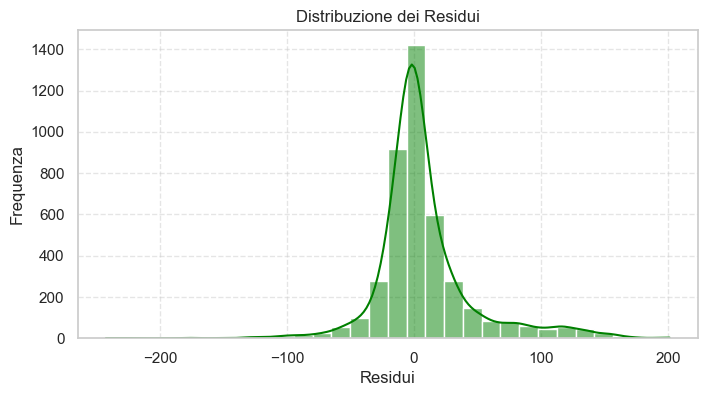

Media dei residui: 7.8911
Deviazione standard dei residui: 38.2490


In [21]:
# Regrssione Lineare Multivariata STANDARD

reg = LinearRegression()


modello_lin_multi_S = reg.fit(reg_x_train_tra, reg_y_train_tra)

y_pred_lin_multi_train_S = reg.predict(reg_x_train_tra)
r2_lin_multi_train_S = reg.score(reg_x_train_tra, reg_y_train_tra)
print(f"R^2 Score: {r2_lin_multi_train_S:.4f}")
print(f"Coefficienti (m): {reg.coef_}")
print(f"Intercetta (q): {reg.intercept_:.4f}")

# Test
y_pred_lin_multi_S = reg.predict(reg_x_test_tra)

x_lin_multi_S_unt = np.exp(reg_x_test_tra)
reg_y_test_tra_unt = np.exp(reg_y_test_tra)
y_pred_lin_multi_S_unt = np.exp(y_pred_lin_multi_S)

r2_lin_multi_S = r2_score(reg_y_test_tra_unt, y_pred_lin_multi_S_unt)
rmse_lin_multi_S = np.sqrt(mean_squared_error(
    reg_y_test_tra_unt, y_pred_lin_multi_S_unt))
mae_lin_multi_S = mean_absolute_error(
    reg_y_test_tra_unt, y_pred_lin_multi_S_unt)
print(f"R^2 Score Test: {r2_lin_multi_S:.4f}")
print(f"RMSE Score Test: {rmse_lin_multi_S:.4f}")
print(f"MAE Score Test: {mae_lin_multi_S:.4f}")

# Bontà Modello
residui_lin_multi_S = reg_y_test_tra_unt - y_pred_lin_multi_S_unt

# Residui vs Valori Predetti

sns.scatterplot(x=y_pred_lin_multi_S_unt.flatten(),
                y=residui_lin_multi_S, alpha=0.6, color='blue')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label="Zero Error")
plt.title("Residui vs Valori Predetti")
plt.xlabel("Valori Predetti")
plt.ylabel("Residui")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Distribuzione dei Residui
sns.histplot(residui_lin_multi_S, kde=True, color='green', bins=30)
plt.title("Distribuzione dei Residui")
plt.xlabel("Residui")
plt.ylabel("Frequenza")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Statistiche descrittive dei residui
# Dovrebbe essere vicina a 0
print(f"Media dei residui: {residui_lin_multi_S.mean():.4f}")
print(f"Deviazione standard dei residui: {residui_lin_multi_S.std():.4f}")

Add  NumWant                        with p-value 0.000000
Add  ComAgeRec                      with p-value 0.000000
Add  GameWeight                     with p-value 0.000000
Add  Age                            with p-value 0.000000
Add  MaxPlayers                     with p-value 0.000000
Add  NumAlternates                  with p-value 0.000000
Add  NumWish                        with p-value 0.000000
Add  MfgAgeRec                      with p-value 0.000000
Add  NumOwned                       with p-value 0.000000
Add  NumUserRatings                 with p-value 0.000000
Add  NumWeightVotes                 with p-value 0.000000
Add  NumExpansions                  with p-value 0.005298
           Feature        VIF
0   NumUserRatings  23.998900
1          NumWish  13.955624
2         NumOwned  12.127127
3          NumWant   9.298279
4   NumWeightVotes   7.997065
5       GameWeight   2.474982
6        ComAgeRec   2.307230
7              Age   2.050821
8    NumAlternates   1.479983
9   

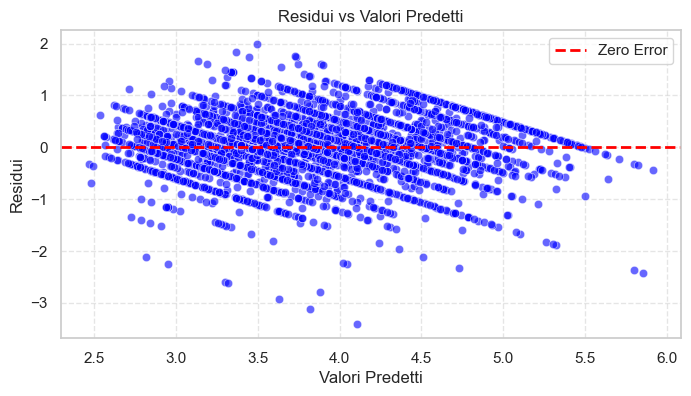

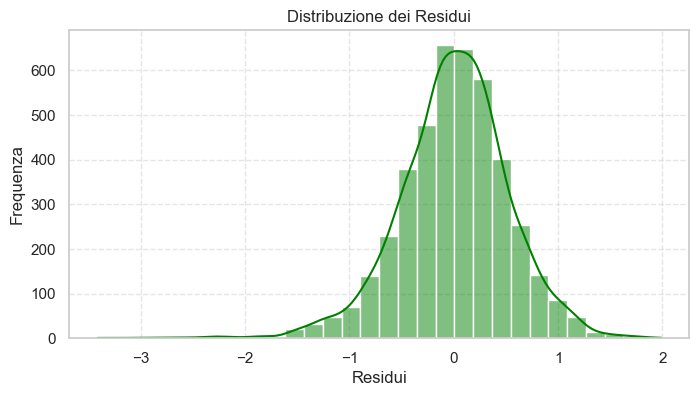

Media dei residui: 0.0032
Deviazione standard dei residui: 0.5293


In [22]:
# Regressione Lineare Multivariata STEPWISE

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
reg = LinearRegression()


def stepwise_selection(X, y, initial_list=[], threshold_in=0.01, threshold_out=0.05, verbose=True):
    included = list(initial_list)

    while True:
        changed = False

        # Forward Selection
        excluded = list(set(X.columns) - set(included))
        new_pval = pd.Series(index=excluded, dtype='float64')

        for new_column in excluded:
            # Addestra modello temporaneo con le feature attuali + la nuova candidata
            model = sm.OLS(y, sm.add_constant(
                X[included + [new_column]])).fit()
            new_pval[new_column] = model.pvalues[new_column]

        if not new_pval.empty:
            best_pval = new_pval.min()
            if best_pval < threshold_in:
                best_feature = new_pval.idxmin()
                included.append(best_feature)
                changed = True
                if verbose:
                    print(
                        f'Add  {best_feature:30} with p-value {best_pval:.6f}')

        # Backward Elimination
        if included:
            model = sm.OLS(y, sm.add_constant(X[included])).fit()
            # Usiamo il p-value di tutte le feature tranne la costante ('const')
            pvalues = model.pvalues.iloc[1:]

            if not pvalues.empty:
                worst_pval = pvalues.max()
                if worst_pval > threshold_out:
                    worst_feature = pvalues.idxmax()
                    included.remove(worst_feature)
                    changed = True
                    if verbose:
                        print(
                            f'Drop {worst_feature:30} with p-value {worst_pval:.6f}')

        # Se non ci sono stati cambiamenti in questo ciclo, termina
        if not changed:
            break

    return included


selected_features = stepwise_selection(
    reg_x_train_tra, reg_y_train_tra, verbose=True)

# VIF
X_for_vif = reg_x_test_tra[selected_features].copy()

X_vif_const = sm.add_constant(X_for_vif, has_constant='add')

vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif_const.values, i)
                   for i in range(X_vif_const.shape[1])]

vif_data = vif_data[vif_data['Feature'] != 'const']
vif_data = vif_data.sort_values(
    by="VIF", ascending=False).reset_index(drop=True)
print(vif_data)

VIF_scarti = []
for index, row in vif_data.iterrows():
    if row["VIF"] >= 3:
        VIF_scarti.append(row["Feature"])
    else:
        continue


selected_features_VIF = [
    feature for feature in selected_features if feature not in VIF_scarti
]

# Modello
x_lin_multi_train = reg_x_train_tra[selected_features_VIF]
modello_lin_multi = reg.fit(x_lin_multi_train, reg_y_train_tra)

y_pred_lin_multi_train = reg.predict(x_lin_multi_train)
r2_lin_multi_train = reg.score(x_lin_multi_train, reg_y_train_tra)
print(f"R^2 Score: {r2_lin_multi_train:.4f}")
print(f"Coefficienti (m): {reg.coef_}")
print(f"Intercetta (q): {reg.intercept_:.4f}")

# Test
x_lin_multi = reg_x_test_tra[selected_features_VIF]
y_pred_lin_multi = reg.predict(x_lin_multi)
r2_lin_multi = reg.score(x_lin_multi, reg_y_test_tra)
rmse_lin_multi = np.sqrt(mean_squared_error(reg_y_test_tra, y_pred_lin_multi))
mae_lin_multi = mean_absolute_error(reg_y_test_tra, y_pred_lin_multi)
print(f"R^2 Score Test: {r2_lin_multi:.4f}")
print(f"RMSE Score Test: {rmse_lin_multi:.4f}")
print(f"MAE Score Test: {mae_lin_multi:.4f}")


# Bontà Modello
residui_lin_multi = reg_y_test_tra - y_pred_lin_multi

# Residui vs Valori Predetti

sns.scatterplot(x=y_pred_lin_multi.flatten(),
                y=residui_lin_multi, alpha=0.6, color='blue')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label="Zero Error")
plt.title("Residui vs Valori Predetti")
plt.xlabel("Valori Predetti")
plt.ylabel("Residui")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Distribuzione dei Residui
sns.histplot(residui_lin_multi, kde=True, color='green', bins=30)
plt.title("Distribuzione dei Residui")
plt.xlabel("Residui")
plt.ylabel("Frequenza")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Statistiche descrittive dei residui
# Dovrebbe essere vicina a 0
print(f"Media dei residui: {residui_lin_multi.mean():.4f}")
print(f"Deviazione standard dei residui: {residui_lin_multi.std():.4f}")

Generazione tomografia per le feature: 'GameWeight' (X) e 'Age' (Y)


C:\Users\Riccardo\AppData\Local\Temp\ipykernel_17784\2174275753.py:62: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right')


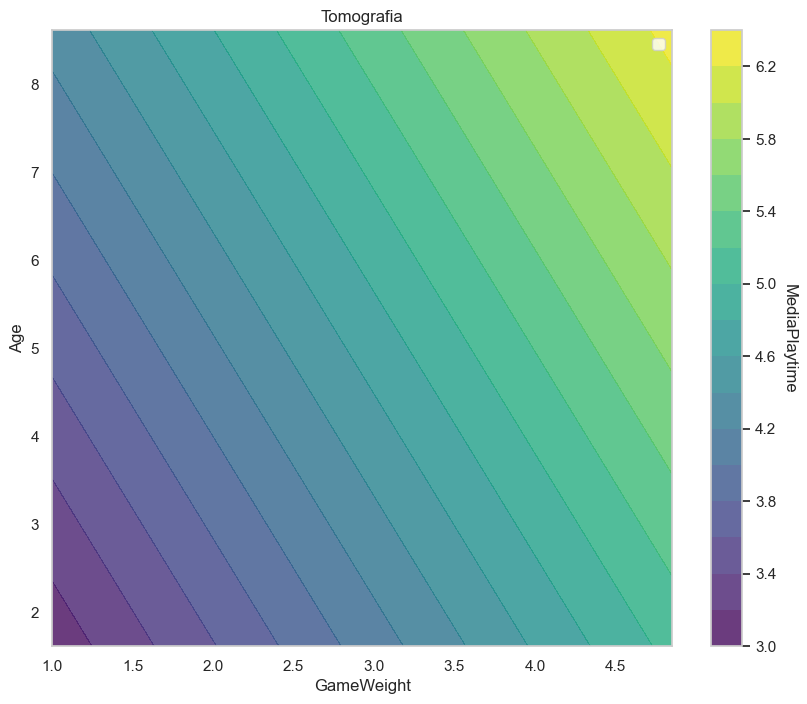

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Identificazione delle due feature più importanti (in valore assoluto)
# Usiamo i coefficienti del modello già addestrato 'reg'
coef_abs = np.abs(reg.coef_)
top_2_indices = np.argsort(coef_abs)[-2:]  # Indici delle 2 feature maggiori
feature_x_name = selected_features_VIF[top_2_indices[1]]  # La più importante
# La seconda più importante
feature_y_name = selected_features_VIF[top_2_indices[0]]

print(
    f"Generazione tomografia per le feature: '{feature_x_name}' (X) e '{feature_y_name}' (Y)")

# 2. Creazione della griglia (Meshgrid) per il "taglio"
# Definiamo i limiti basati sui dati reali
x_min, x_max = x_lin_multi[feature_x_name].min(
), x_lin_multi[feature_x_name].max()
y_min, y_max = x_lin_multi[feature_y_name].min(
), x_lin_multi[feature_y_name].max()

# Generiamo 100x100 punti per la risoluzione del grafico
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                     np.linspace(y_min, y_max, 100))

# 3. Preparazione dei dati di input per il modello
# Dobbiamo fornire valori per TUTTE le feature.
# Le due feature selezionate variano, le altre sono fisse alla media.
input_grid = pd.DataFrame(columns=selected_features_VIF, index=range(xx.size))

# Riempiamo tutto con le medie
means = x_lin_multi.mean()
for col in selected_features_VIF:
    input_grid[col] = means[col]

# Sovrascriviamo le due colonne che stiamo variando
input_grid[feature_x_name] = xx.ravel()
input_grid[feature_y_name] = yy.ravel()

# 4. Predizione sul piano di taglio
Z = reg.predict(input_grid)
Z = Z.reshape(xx.shape)

# 5. Visualizzazione (Tomografia)
plt.figure(figsize=(10, 8))

# Contour plot riempito (la "mappa termica" dell'iperpiano)
contour = plt.contourf(xx, yy, Z, levels=20, cmap='viridis', alpha=0.8)
cbar = plt.colorbar(contour)
cbar.set_label('MediaPlaytime', rotation=270, labelpad=15)

# Aggiunta (opzionale) dello scatter plot dei dati reali proiettati su questo piano
# Attenzione: i punti potrebbero sembrare "fuori posto" perché le loro altre dimensioni
# non sono alla media, ma aiuta a capire la densità dei dati in quest'area.
'''plt.scatter(x_lin_multi[feature_x_name], x_lin_multi[feature_y_name], 
            c='black', s=20, alpha=0.2, edgecolor='white', label='Dati Reali (Proiezione)')'''

plt.title(f"Tomografia")
plt.xlabel(f"{feature_x_name}")
plt.ylabel(f"{feature_y_name}")
plt.legend(loc='upper right')
plt.grid(False)  # La griglia è data dai colori
plt.show()

In [24]:
# Regressione Lineare Ridge

# Ricerca di alpha migliore
ricerca_alpha_ridge = RidgeCV(cv=10).fit(
    reg_x_train_tra, reg_y_train_tra)
best_alpha_ridge = ricerca_alpha_ridge.alpha_   # Minimizza MSE
print(f"Miglior Alpha: {best_alpha_ridge}")


ridge = Ridge(alpha=best_alpha_ridge)

# Modello e risultati Training
modello_ridge = ridge.fit(reg_x_train_tra, reg_y_train_tra)
y_pred_ridge_train = ridge.predict(reg_x_train_tra)
r2_ridge_train = ridge.score(reg_x_train_tra, reg_y_train_tra)
print(f"R^2 Score Training: {r2_ridge_train:.4f}")
print(f"Coefficiente (m): {ridge.coef_}")
print(f"Intercetta (q): {ridge.intercept_:.4f}")

# Test
y_pred_ridge = ridge.predict(reg_x_test_tra)
r2_ridge = ridge.score(reg_x_test_tra, reg_y_test_tra)

x_ridge_unt = np.exp(reg_x_test_tra)
reg_y_test_tra_unt = np.exp(reg_y_test_tra)
y_pred_ridge_unt = np.exp(y_pred_ridge)

rmse_ridge = np.sqrt(mean_squared_error(reg_y_test_tra_unt, y_pred_ridge_unt))
mae_ridge = mean_absolute_error(reg_y_test_tra_unt, y_pred_ridge_unt)
print(f"R^2 Score Test: {r2_ridge:.4f}")
print(f"RMSE Score Test: {rmse_ridge:.4f}")
print(f"MAE Score Test: {mae_ridge:.4f}")

Miglior Alpha: 10.0
R^2 Score Training: 0.5858
Coefficiente (m): [ 4.65021394e-01  1.68067287e-02  1.23367678e-01  6.36125071e-02
 -3.70217339e-05  1.76915962e-01  9.55890009e-02 -4.58724398e-02
  8.97144748e-02  1.12829485e-02 -2.51474687e-01 -4.86014926e-02
 -1.75218952e-02  1.13358839e-03  1.38814114e-01]
Intercetta (q): 1.5018
R^2 Score Test: 0.5862
RMSE Score Test: 39.0559
MAE Score Test: 23.7235


c:\Users\Riccardo\anaconda3\Lib\site-packages\pandas\core\internals\blocks.py:393: RuntimeWarning: overflow encountered in exp
  result = func(self.values, **kwargs)


In [25]:
# Regressione Lineare Lasso

# Ricerca di alpha migliore
ricerca_alpha_lasso = LassoCV(cv=10, random_state=222, max_iter=10000).fit(
    reg_x_train_tra, reg_y_train_tra)
best_alpha_lasso = ricerca_alpha_lasso.alpha_   # Minimizza MSE
print(f"Miglior Alpha: {best_alpha_lasso}")


lasso = Lasso(alpha=best_alpha_lasso)

# Modello e risultati Training
modello_lasso = lasso.fit(reg_x_train_tra, reg_y_train_tra)
y_pred_lasso_train = lasso.predict(reg_x_train_tra)
r2_lasso_train = lasso.score(reg_x_train_tra, reg_y_train_tra)
print(f"R^2 Score Training: {r2_lasso_train:.4f}")
print(f"Coefficiente (m): {lasso.coef_}")
print(f"Intercetta (q): {lasso.intercept_:.4f}")

# Test
y_pred_lasso = lasso.predict(reg_x_test_tra)
r2_lasso = lasso.score(reg_x_test_tra, reg_y_test_tra)

x_lasso_unt = np.exp(reg_x_test_tra)
reg_y_test_tra_unt = np.exp(reg_y_test_tra)
y_pred_lasso_unt = np.exp(y_pred_lasso)

rmse_lasso = np.sqrt(mean_squared_error(reg_y_test_tra_unt, y_pred_lasso_unt))
mae_lasso = mean_absolute_error(reg_y_test_tra_unt, y_pred_lasso_unt)
print(f"R^2 Score Test: {r2_lasso:.4f}")
print(f"RMSE Score Test: {rmse_lasso:.4f}")
print(f"MAE Score Test: {mae_lasso:.4f}")

Miglior Alpha: 0.01056320163922842
R^2 Score Training: 0.5758
Coefficiente (m): [ 4.46220331e-01  0.00000000e+00  4.24512419e-02  7.65691433e-02
 -6.90551103e-05  3.29314805e-02  3.81442210e-02 -0.00000000e+00
  2.61104998e-02  9.73107226e-03 -6.51608866e-02 -2.54647810e-02
 -0.00000000e+00 -0.00000000e+00  1.42172390e-01]
Intercetta (q): 1.5852
R^2 Score Test: 0.5789
RMSE Score Test: 40.1041
MAE Score Test: 24.2717


c:\Users\Riccardo\anaconda3\Lib\site-packages\pandas\core\internals\blocks.py:393: RuntimeWarning: overflow encountered in exp
  result = func(self.values, **kwargs)


In [ ]:
# Regressione Non-Lineare Knn Semplice

# --- 1. CONFIGURAZIONE E TRAINING ---
k_reg_sem = 126
knn_regressor = KNeighborsRegressor(n_neighbors=k_reg_sem, weights='uniform')

# Prepariamo i dati di training (Reshape necessario per renderli 2D: n_samples, 1 feature)
x_knn_sem_train = reg_x_train_tra_sca[["GameWeight"]].values.reshape(-1, 1)
modello_knn_sem = knn_regressor.fit(x_knn_sem_train, reg_y_train_tra_sca)

# --- 2. PREDIZIONE ---
# Prepariamo i dati di test
x_knn_sem = reg_x_test_tra_sca[["GameWeight"]].values.reshape(-1, 1)
y_pred_knn_sem = knn_regressor.predict(x_knn_sem)

# Calcolo R2 sui dati scalati
r2_knn_sem = r2_score(reg_y_test_tra_sca, y_pred_knn_sem)

# --- 3. INVERSE TRANSFORM (MANUALE) ---
# Calcoliamo Mean e Std dai dati di TRAINING originali (logaritmici)
# ddof=0 serve per replicare il comportamento di StandardScaler (popolazione vs campione)
mean_y = train_reg_tra["MediaPlaytime"].mean()
std_y = train_reg_tra["MediaPlaytime"].std(ddof=0)

# Applichiamo la formula inversa: (Predizione * Std) + Mean
y_pred_tra_sca_unt = (y_pred_knn_sem * std_y) + mean_y

# --- 4. INVERSE LOG (ESPONENZIALE) ---
# Recuperiamo i target reali di test (formato log)
reg_y_test_tra_sca_unt = test_reg_tra["MediaPlaytime"]

# Applichiamo l'esponenziale per tornare all'unità di misura originale (es. minuti/ore)
reg_y_test_tra_sca_unt = np.exp(reg_y_test_tra_sca_unt)
y_pred_tra_sca_unt = np.exp(y_pred_tra_sca_unt)

# (Opzionale) Se vuoi anche la X originale
x_knn_sem_unt = np.exp(test_reg_tra["GameWeight"])

# --- 5. VALUTAZIONE ---
rmse_knn_sem = np.sqrt(mean_squared_error(
    reg_y_test_tra_sca_unt, y_pred_tra_sca_unt))
mae_knn_sem = mean_absolute_error(reg_y_test_tra_sca_unt, y_pred_tra_sca_unt)

print(f"R^2 Score Test: {r2_knn_sem:.4f}")
print(f"RMSE Score Test: {rmse_knn_sem:.4f}")
print(f"MAE Score Test: {mae_knn_sem:.4f}")

R^2 Score Test: 0.5047
RMSE Score Test: 43.2120
MAE Score Test: 26.7233


In [ ]:
# Regressione Non-Lineare Knn Multivariata STANDARD

# --- 1. CONFIGURAZIONE E TRAINING ---
k_reg_sem = 126
knn_regressor = KNeighborsRegressor(n_neighbors=k_reg_sem, weights='uniform')

# Modello Multivariato
# Qui reg_x_train_tra_sca ha già più colonne, quindi non serve reshape
modello_knn_multi_S = knn_regressor.fit(
    reg_x_train_tra_sca, reg_y_train_tra_sca)

# --- 2. PREDIZIONE ---
y_pred_knn_multi_S = knn_regressor.predict(reg_x_test_tra_sca)

# Calcolo R2 (sui dati scalati va bene per valutare la varianza spiegata)
r2_knn_multi_S = r2_score(reg_y_test_tra_sca, y_pred_knn_multi_S)

# --- 3. INVERSE TRANSFORM (MANUALE) ---
# Usiamo gli stessi parametri (Mean e Std) del target di training usati prima.
# Questo passaggio è identico al modello semplice, perché la Y è la stessa.
mean_y = train_reg_tra["MediaPlaytime"].mean()
std_y = train_reg_tra["MediaPlaytime"].std(ddof=0)

# Formula inversa: (Predizione * Std) + Mean
y_pred_multi_unt = (y_pred_knn_multi_S * std_y) + mean_y

# --- 4. INVERSE LOG (ESPONENZIALE) ---
# Recuperiamo il target reale non scalato (logaritmico) dal dataset di test originale
reg_y_test_unt = test_reg_tra["MediaPlaytime"]

# Esponenziale per tornare all'unità originale (es. minuti)
reg_y_test_final = np.exp(reg_y_test_unt)
y_pred_multi_final = np.exp(y_pred_multi_unt)

# --- 5. CALCOLO METRICHE REALI ---
rmse_knn_multi_S = np.sqrt(mean_squared_error(
    reg_y_test_final, y_pred_multi_final))
mae_knn_multi_S = mean_absolute_error(reg_y_test_final, y_pred_multi_final)

print(f"R^2 Score Test: {r2_knn_multi_S:.4f}")
print(f"RMSE Score Test: {rmse_knn_multi_S:.4f}")
print(f"MAE Score Test: {mae_knn_multi_S:.4f}")

R^2 Score Test: 0.5962
RMSE Score Test: 39.3305
MAE Score Test: 23.7772


In [28]:
# Regressione Non-Lineare Decision Tree Semplice

albero_regressore = DecisionTreeRegressor(max_depth=7,
                                          random_state=222)

# Modello
x_tree_sem_train = reg_x_train_imp[["GameWeight"]].values.reshape(-1, 1)
modello_tree_semp = albero_regressore.fit(x_tree_sem_train, reg_y_train_imp)

# Test
x_tree_sem = reg_x_test_imp[["GameWeight"]].values.reshape(-1, 1)
y_pred_tree_sem = albero_regressore.predict(x_tree_sem)
r2_tree_sem = r2_score(reg_y_test_imp, y_pred_tree_sem)

rmse_tree_sem = np.sqrt(mean_squared_error(reg_y_test_imp, y_pred_tree_sem))
mae_tree_sem = mean_absolute_error(reg_y_test_imp, y_pred_tree_sem)

print(f"R^2 Score Test: {r2_tree_sem:.4f}")
print(f"RMSE Score Test: {rmse_tree_sem:.4f}")
print(f"MAE Score Test: {mae_tree_sem:.4f}")

R^2 Score Test: 0.4793
RMSE Score Test: 41.6643
MAE Score Test: 27.4791


In [29]:
# Regressione Non-Lineare Decision Tree Multivariata

albero_regressore = DecisionTreeRegressor(max_depth=7,
                                          random_state=222)

# Modello
modello_tree_multi_S = albero_regressore.fit(reg_x_train_imp, reg_y_train_imp)

# Test
y_pred_tree_multi_S = albero_regressore.predict(reg_x_test_imp)
r2_tree_multi_S = r2_score(reg_y_test_imp, y_pred_tree_multi_S)
rmse_tree_multi_S = np.sqrt(
    mean_squared_error(reg_y_test_imp, y_pred_tree_multi_S))
mae_tree_multi_S = mean_absolute_error(reg_y_test_imp, y_pred_tree_multi_S)

print(f"R^2 Score Test: {r2_tree_multi_S:.4f}")
print(f"RMSE Score Test: {rmse_tree_multi_S:.4f}")
print(f"MAE Score Test: {mae_tree_multi_S:.4f}")

R^2 Score Test: 0.5842
RMSE Score Test: 37.2289
MAE Score Test: 23.3950


In [35]:
# Tabella per comparazione

df_comparazione = pd.DataFrame(
    columns=["Modello", "Complessità", "R^2", "MAE", "RMSE"])

# Lineare Semplice
df_comparazione.loc[len(df_comparazione)] = {
    "Modello": "Lineare", "Complessità": "Semplice", "R^2": r2_lin_sem, "MAE": mae_lin_sem, "RMSE": rmse_lin_sem}

# Lineare Multivariato (Stepwise)
df_comparazione.loc[len(df_comparazione)] = {
    "Modello": "Lineare", "Complessità": "Multivariato", "R^2": r2_lin_multi, "MAE": mae_lin_multi, "RMSE": rmse_lin_multi}

# Lineare Ridge
df_comparazione.loc[len(df_comparazione)] = {
    "Modello": "Lineare Ridge", "Complessità": "Multivariato", "R^2": r2_ridge, "MAE": mae_ridge, "RMSE": rmse_ridge}

# Lineare Lasso
df_comparazione.loc[len(df_comparazione)] = {
    "Modello": "Lineare Lasso", "Complessità": "Multivariato", "R^2": r2_lasso, "MAE": mae_lasso, "RMSE": rmse_lasso}

# Knn Semplice
df_comparazione.loc[len(df_comparazione)] = {
    "Modello": "Non Lineare Knn", "Complessità": "Semplice", "R^2": r2_knn_sem, "MAE": mae_knn_sem, "RMSE": rmse_knn_sem}

# Knn Multivariato
df_comparazione.loc[len(df_comparazione)] = {
    "Modello": "Non Lineare Knn", "Complessità": "Multivariato", "R^2": r2_knn_multi_S, "MAE": mae_knn_multi_S, "RMSE": rmse_knn_multi_S}

# Deciosin Tree Semplice
df_comparazione.loc[len(df_comparazione)] = {
    "Modello": "Non Lineare Decision Tree", "Complessità": "Semplice", "R^2": r2_tree_sem, "MAE": mae_tree_sem, "RMSE": rmse_tree_sem}

# Deciosin Tree SempMultivariatolice
df_comparazione.loc[len(df_comparazione)] = {
    "Modello": "Non Lineare Decision Tree", "Complessità": "Multivariato", "R^2": r2_tree_multi_S, "MAE": mae_tree_multi_S, "RMSE": rmse_tree_multi_S}

print(df_comparazione)

                     Modello   Complessità       R^2        MAE       RMSE
0                    Lineare      Semplice  0.498622  26.812137  44.600084
1                    Lineare  Multivariato  0.574371   0.400635   0.529211
2              Lineare Ridge  Multivariato  0.586192  23.723482  39.055888
3              Lineare Lasso  Multivariato  0.578881  24.271691  40.104143
4            Non Lineare Knn      Semplice  0.504666  26.723285  43.212038
5            Non Lineare Knn  Multivariato  0.596204  23.777237  39.330519
6  Non Lineare Decision Tree      Semplice  0.479284  27.479114  41.664278
7  Non Lineare Decision Tree  Multivariato  0.584248  23.395026  37.228897


In [ ]:
# COSE DA FARE:
# cretino fai curva ROC
# qqplot

# IMPORTANTE
# usare dataset trasformato per ridge, lasso, knn e reg lin; anche per classification knn(transformed + scaled) e naive (transf e basta)
# usare dataset og per tree